In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader

In [2]:
# Replace with the exact file path from Kaggle's input panel.
MANIFEST_PATH = Path(
    "/kaggle/input/notebooks/zidanefatuna/"
    "07-batch-dicom-to-volume-preprocessing/"
    "preprocessed/processed_manifest.csv"
)

DATA_ROOT = MANIFEST_PATH.parent

manifest = pd.read_csv(
    MANIFEST_PATH,
    dtype={
        "StudyInstanceUID": str,
        "SeriesInstanceUID": str,
    },
)

assert len(manifest) == 174
assert manifest["status"].eq("ok").all()
assert manifest["StudyInstanceUID"].nunique() == 58

missing_files = [
    relative_path
    for relative_path in manifest["processed_relative_path"]
    if not (DATA_ROOT / relative_path).is_file()
]

print("Series:", len(manifest))
print("Studies:", manifest["StudyInstanceUID"].nunique())
print("Missing processed files:", len(missing_files))

assert not missing_files, "Check DATA_ROOT and the attached output files."

print("\nStudies per split:")
print(
    manifest[["StudyInstanceUID", "split"]]
    .drop_duplicates()["split"]
    .value_counts()
)

Series: 174
Studies: 58
Missing processed files: 0

Studies per split:
split
train         46
validation    12
Name: count, dtype: int64


In [3]:
TARGET_COLUMNS = [
    "ACL", "MCL",
    "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA",
    "Effusion", "Synovitis", "Baker's",
    "Contusion", "Fracture",
]

PLANES = ("Sagittal", "Coronal", "Axial")


class KneeStudyDataset(Dataset):
    def __init__(self, manifest, data_root, split):
        self.data_root = Path(data_root)
        rows = manifest.loc[manifest["split"].eq(split)].copy()

        if rows.empty:
            raise ValueError(f"No studies found for split: {split}")

        self.studies = []

        for study_id, group in rows.groupby("StudyInstanceUID", sort=True):
            if (
                len(group) != len(PLANES)
                or set(group["Anatomical_Plane"]) != set(PLANES)
            ):
                raise ValueError(f"Expected one series per plane: {study_id}")

            labels = group[TARGET_COLUMNS].to_numpy(dtype=np.float32)

            if not np.isin(labels, [0, 1]).all():
                raise ValueError(f"Invalid labels: {study_id}")

            if not np.all(labels == labels[0]):
                raise ValueError(f"Inconsistent study labels: {study_id}")

            by_plane = group.set_index("Anatomical_Plane")

            self.studies.append({
                "study_id": study_id,
                "paths": {
                    plane: by_plane.loc[plane, "processed_relative_path"]
                    for plane in PLANES
                },
                "labels": labels[0].copy(),
            })

    def __len__(self):
        return len(self.studies)

    def __getitem__(self, index):
        study = self.studies[index]
        images = {}

        for plane in PLANES:
            volume = np.load(
                self.data_root / study["paths"][plane],
                allow_pickle=False,
            )

            if volume.ndim != 3 or volume.shape[1:] != (224, 224):
                raise ValueError(f"Unexpected volume shape: {volume.shape}")

            # (slices, height, width) → (channel, slices, height, width)
            images[plane] = torch.from_numpy(
                np.ascontiguousarray(volume, dtype=np.float32)
            ).unsqueeze(0)

        return {
            "study_id": study["study_id"],
            "images": images,
            "labels": torch.from_numpy(study["labels"].copy()),
        }

In [4]:
train_dataset = KneeStudyDataset(manifest, DATA_ROOT, split="train")
validation_dataset = KneeStudyDataset(
    manifest, DATA_ROOT, split="validation"
)

sample = train_dataset[0]

print("Training studies:", len(train_dataset))
print("Validation studies:", len(validation_dataset))

for plane, image in sample["images"].items():
    print(plane, tuple(image.shape), image.dtype)

print("Labels:", sample["labels"])
print("Label shape:", tuple(sample["labels"].shape))

Training studies: 46
Validation studies: 12
Sagittal (1, 36, 224, 224) torch.float32
Coronal (1, 30, 224, 224) torch.float32
Axial (1, 32, 224, 224) torch.float32
Labels: tensor([0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0.])
Label shape: (12,)


In [5]:
train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42),
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)

batch = next(iter(train_loader))

for plane, images in batch["images"].items():
    print(plane, tuple(images.shape))

print("Labels:", tuple(batch["labels"].shape))
print("Study IDs:", batch["study_id"])

Sagittal (1, 1, 36, 224, 224)
Coronal (1, 1, 30, 224, 224)
Axial (1, 1, 32, 224, 224)
Labels: (1, 12)
Study IDs: ['1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149']


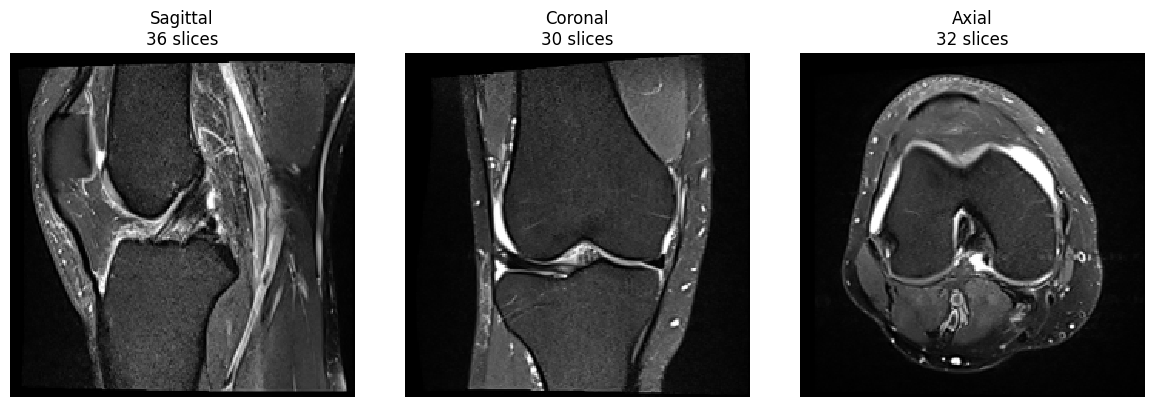

Study: 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
Positive study labels: ['PF OA', 'Effusion']


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, plane in zip(axes, PLANES):
    # Remove batch and channel axes: (1, 1, D, H, W) → (D, H, W).
    volume = batch["images"][plane][0, 0]
    middle = volume.shape[0] // 2

    ax.imshow(
        volume[middle].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest",
    )
    ax.set_title(f"{plane}\n{volume.shape[0]} slices")
    ax.axis("off")

plt.tight_layout()
plt.show()

positive_targets = [
    name
    for name, value in zip(TARGET_COLUMNS, batch["labels"][0].tolist())
    if value == 1
]

print("Study:", batch["study_id"][0])
print("Positive study labels:", positive_targets)

## Conclusions

- The Dataset contains 46 training studies and 12 validation studies.
- Each example loads three selected plane volumes from the same study
  and one 12-element binary label vector.
- Volumes are loaded as float32 tensors with shape
  (channel, slices, height, width).
- Batch size 1 preserves variable slice counts without depth padding
  or slice sampling. Batched volumes have shape
  (1, 1, slice_count, 224, 224), and labels have shape (1, 12).
- The training loader shuffles studies; validation uses a fixed order.
- A same-study preview displayed the expected plane views and dimensions.
  This is a loading check, not clinical validation of the labels.
- No augmentation is currently applied, establishing a reference setup
  for later augmentation comparisons.